# Big Data Analytics - Project 1
## Limelight Official (YouTube): from 470 videos to a marketing decision

**Business question:** Which kinds of Limelight videos get the most attention and the best audience response, and what should the marketing team publish and test next?

**Dataset:** `Limelight_YouTube_Data.csv` - public metadata of videos on the *Limelight Official* YouTube channel (title, description, publish date, views, likes, comment count, duration, tags, URL).

**Source / provenance note:** The dataset was collected by me using the YouTube Data API v3 on 8 November 2026. It contains public metadata of the videos on the Limelight Official YouTube channel (470 videos, published between November 2018 and November 2026): title, description, publish date, views, likes, comment count, duration, tags and URL. Views, likes and comments are a snapshot of the collection date and will change over time. The data was collected through the official API and used only for this academic project.

**Prepared by:** Zulain Khan, f2023332089  |  **Date:** 08/11/2026

**Tools:** CSV + Google Colab + Pandas + Matplotlib

## Step 1: Load the data
Upload `Limelight_YouTube_Data.csv` to Colab (folder icon on the left). Keep an untouched backup copy of the original file.

In [12]:
import pandas as pd, numpy as np, re, time, os, math
import matplotlib.pyplot as plt

# Simple, readable chart style: one hue for magnitude, light grid, no top/right box
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True,
    'axes.titleweight': 'bold', 'axes.titlesize': 11,
})
BLUE = '#3266AD'

df = pd.read_csv('Limelight_YouTube_Data.csv')
print(df.shape)
display(df.head())
df.info()

(470, 11)


,Video_ID,Title,Description,Published_Date,Channel_Name,Views,Likes,Comments_Count,Duration,Tags,Video_URL
0,Eij2WfEQwac,Limelight Official Online Store in Pakistan | ...,Your Cart Is Calling.\n\nShop Now: https://www...,2026-11-06 11:07:18+00:00,Limelight Official,871,5,0.0,PT15S,"limelight, limelight.pk, limelight official, l...",https://www.youtube.com/watch?v=Eij2WfEQwac
1,pWA1fyKy-P0,Limelight Official Online Store in Pakistan | ...,Your Wishlist Awaits!\n\nShop Now: https://www...,2026-11-06 10:23:47+00:00,Limelight Official,307,1,0.0,PT5S,"limelight, limelight.pk, limelight official, l...",https://www.youtube.com/watch?v=pWA1fyKy-P0
2,GjINBWIexyc,Limelight Official Online Store in Pakistan | ...,It's the sale you've been waiting for!\n\nShop...,2026-11-06 10:14:33+00:00,Limelight Official,585,1,0.0,PT8S,"limelight, limelight.pk, limelight official, l...",https://www.youtube.com/watch?v=GjINBWIexyc
3,Qmxy6wX9VtU,Limelight Official Online Store in Pakistan | ...,"More Style, Less Spend.\n\nShop Now: https://w...",2026-11-06 10:09:55+00:00,Limelight Official,227,1,0.0,PT11S,"limelight, limelight.pk, limelight official, l...",https://www.youtube.com/watch?v=Qmxy6wX9VtU
4,Zulz3QGcky0,Limelight Official Online Store in Pakistan | ...,Flat 30% OFF on Entire Stock!\n\nShop Now: htt...,2026-11-06 10:06:50+00:00,Limelight Official,313,3,0.0,PT7S,"limelight, limelight.pk, limelight official, l...",https://www.youtube.com/watch?v=Zulz3QGcky0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 470 entries, 0 to 469
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Video_ID        470 non-null    object 
 1   Title           470 non-null    object 
 2   Description     453 non-null    object 
 3   Published_Date  470 non-null    object 
 4   Channel_Name    470 non-null    object 
 5   Views           470 non-null    int64  
 6   Likes           470 non-null    int64  
 7   Comments_Count  464 non-null    float64
 8   Duration        470 non-null    object 
 9   Tags            449 non-null    object 
 10  Video_URL       470 non-null    object 
dtypes: float64(1), int64(2), object(8)
memory usage: 40.5+ KB


## Step 2: Data objects and attributes (data dictionary)
**One row = one YouTube video** published by the Limelight Official channel. (Not a user, comment or campaign.)

| Column | Type | Meaning |
|---|---|---|
| Video_ID | identifier (text) | Unique YouTube video id |
| Title | text | Video title |
| Description | text | Video description (contains links and hashtags) |
| Published_Date | date/time | When the video was published (UTC) |
| Channel_Name | categorical | Always "Limelight Official" (single channel) |
| Views | numerical (count) | Public view count when the data was collected |
| Likes | numerical (count) | Public like count |
| Comments_Count | numerical (count) | Public comment count (some values missing) |
| Duration | text (ISO 8601, e.g. PT15S) | Video length; converted to seconds below |
| Tags | text | Creator-supplied tags (see quality note below) |
| Video_URL | text | Link to the video |

**Types of data in this project:** text (title, description, tags), dates, categories, counts (views, likes, comments) and duration.

## Step 3: Quality checks
Do not delete missing values automatically - first ask what they mean. A blank comment count may mean "not collected", not zero.

In [13]:
print("Rows, columns:", df.shape)
display(df.dtypes)
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Video_IDs:", df['Video_ID'].duplicated().sum())
print("Repeated titles:", df['Title'].duplicated().sum(), "(same title used on different videos)")
display(df.describe(include='all').T)

Rows, columns: (470, 11)


,0
Video_ID,object
Title,object
Description,object
Published_Date,object
Channel_Name,object
Views,int64
Likes,int64
Comments_Count,float64
Duration,object
Tags,object


,0
Video_ID,0
Title,0
Description,17
Published_Date,0
Channel_Name,0
Views,0
Likes,0
Comments_Count,6
Duration,0
Tags,21


Duplicate rows: 0
Duplicate Video_IDs: 0
Repeated titles: 102 (same title used on different videos)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Video_ID,470,470,Eij2WfEQwac,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Title,470,368,Limelight Official Online Store in Pakistan | ...,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,453,378,Shop Now: https://www.limelight.pk/\r\nSubscri...,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Published_Date,470,470,2026-11-06 11:07:18+00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Channel_Name,470,1,Limelight Official,470,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Views,470.0,NaN,NaN,NaN,45045.029787,133428.370806,35.0,288.25,1402.5,9329.75,1441141.0
Likes,470.0,NaN,NaN,NaN,144.395745,1608.402702,0.0,2.0,9.0,26.0,33891.0
Comments_Count,464.0,NaN,NaN,NaN,0.793103,4.228398,0.0,0.0,0.0,1.0,82.0
Duration,470,54,PT15S,149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tags,449,103,"limelight, limelight.pk, limelight official, l...",248,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# Convert types (keep the original columns untouched, add new ones)
df['published'] = pd.to_datetime(df['Published_Date'], errors='coerce', utc=True)
df['pub_year'] = df['published'].dt.year
df['duration_s'] = pd.to_timedelta(df['Duration'], errors='coerce').dt.total_seconds()
df['title_len'] = df['Title'].fillna('').str.len()

print("Date range:", df['published'].min().date(), "to", df['published'].max().date())
print("Unparsed dates:", df['published'].isna().sum(), "| unparsed durations:", df['duration_s'].isna().sum())
print("Videos with 0 likes:", (df['Likes'] == 0).sum())
print("Videos with missing Comments_Count:", df['Comments_Count'].isna().sum())

# Tags look generic: check whether old-season tags appear on recent videos
print()
print("Most common tag string:")
print(df['Tags'].value_counts().head(1))
print()
print("How long are the videos?")
print(df['duration_s'].describe())
print("Share of videos 60 seconds or shorter:", round((df['duration_s'] <= 60).mean() * 100, 1), "%")

Date range: 2018-11-04 to 2026-11-06
Unparsed dates: 0 | unparsed durations: 0
Videos with 0 likes: 36
Videos with missing Comments_Count: 6

Most common tag string:
Tags
limelight, limelight.pk, limelight official, limelight winter collection 2019, limelight 2019, limelight winter    248
Name: count, dtype: int64

How long are the videos?
count    470.000000
mean      18.000000
std       12.759878
min        3.000000
25%       13.000000
50%       15.000000
75%       16.000000
max      110.000000
Name: duration_s, dtype: float64
Share of videos 60 seconds or shorter: 98.7 %


**Quality notes:**
- `Video_ID` is unique, so there are no duplicate records; but some *titles* repeat (for example a generic store-promo title), so titles cannot be used as identifiers.
- `Comments_Count` has a few missing values. They are kept as missing (not replaced by 0) and ignored in comment averages.
- `Description` and `Tags` have some missing values. The tags look channel-wide defaults (e.g. a "winter collection 2019" tag on a 2026 video), so tags are **not** used to classify content.
- Almost all videos are 60 seconds or shorter (short-form), so duration cannot be used to compare long vs short videos.
- Views, likes and comments are a **snapshot**: older videos had more time to collect views.

## Step 4: EDA - build a content category and run the statistics
Tags are unreliable, so content type is derived from the **video title** using simple keyword rules. This is an approximation made for this project, not an official label.

In [15]:
def categorize(title):
    s = str(title).lower()
    if re.search(r'\bsale\b|% ?off|\boff\b|discount', s):                 return 'Sale / discount'
    if 'eid' in s:                                                          return 'Eid'
    if re.search(r'unstitched|lawn|cambric|fabric', s):                     return 'Unstitched / fabric'
    if re.search(r'pret|kurti|western|ready|rtw|formal|co-?ord|[23][- ]?piece', s): return 'Pret / ready-to-wear'
    if re.search(r'jewel|bag|wallet|shoe|footwear|accessor', s):            return 'Accessories'
    if re.search(r'winter|khaddar|velvet|shawl', s):                        return 'Winter'
    if re.search(r'online store|limelight\.pk', s):                         return 'Generic store promo'
    return 'Other'

df['category'] = df['Title'].map(categorize)
df['like_rate_pct'] = df['Likes'] / df['Views'] * 100      # likes per 100 views (Views > 0 for all rows)

print("Videos per category:")
display(df['category'].value_counts())

Videos per category:


,count
category,
Unstitched / fabric,138
Pret / ready-to-wear,95
Eid,78
Sale / discount,59
Generic store promo,34
Other,34
Accessories,22
Winter,10


In [16]:
print("Summary statistics (count, mean, median, max):")
display(df[['Views','Likes','Comments_Count','like_rate_pct']].describe().round(2))

print("Mean is", round(df['Views'].mean() / df['Views'].median(), 1), "times the median for Views -> a few videos dominate the average.")
top10 = df.nlargest(10, 'Views')['Views'].sum() / df['Views'].sum() * 100
print(f"Top 10 videos ({10/len(df)*100:.1f}% of videos) hold {top10:.1f}% of all views.")

print()
print("Top 5 videos by views:")
display(df.nlargest(5, 'Views')[['Title','published','Views','Likes','Comments_Count']])

Summary statistics (count, mean, median, max):


,Views,Likes,Comments_Count,like_rate_pct
count,470.00,470.0,464.00,470.00
mean,45045.03,144.4,0.79,0.98
std,133428.37,1608.4,4.23,1.13
min,35.00,0.0,0.00,0.00
25%,288.25,2.0,0.00,0.09
50%,1402.50,9.0,0.00,0.85
75%,9329.75,26.0,1.00,1.45
max,1441141.00,33891.0,82.00,13.75


Mean is 32.1 times the median for Views -> a few videos dominate the average.
Top 10 videos (2.1% of videos) hold 33.6% of all views.

Top 5 videos by views:


,Title,published,Views,Likes,Comments_Count
160,Eid Unstitched Embroidered ’24 by Limelight.pk...,2024-03-29 11:52:15+00:00,1441141,242,6.0
98,Introducing Unstitched Lawn ‘25 — the ultimate...,2025-02-21 12:40:39+00:00,1073732,7,0.0
396,Limelight End of Season SALE is live! Shop you...,2020-01-21 10:15:08+00:00,739477,55,2.0
346,Limelight Unstitched Cambric - The true essenc...,2021-09-25 09:24:30+00:00,592592,26,0.0
164,Eid Unstitched by Limelight - Available In-sto...,2024-03-11 09:21:02+00:00,570074,33891,3.0


In [17]:
cat = (df.groupby('category')
         .agg(videos=('Views', 'size'),
              median_views=('Views', 'median'),
              mean_views=('Views', 'mean'),
              median_likes=('Likes', 'median'),
              median_like_rate_pct=('like_rate_pct', 'median'),
              mean_comments=('Comments_Count', 'mean'))
         .round(2)
         .sort_values('videos', ascending=False))
display(cat)
print("Correlations (Views, Likes, Comments_Count, duration_s):")
display(df[['Views','Likes','Comments_Count','duration_s']].corr().round(2))

,videos,median_views,mean_views,median_likes,median_like_rate_pct,mean_comments
category,,,,,,
Unstitched / fabric,138,1952.0,44200.54,17.5,1.13,1.26
Pret / ready-to-wear,95,1377.0,26074.38,7.0,0.90,0.35
Eid,78,2123.0,84464.40,7.0,0.35,0.96
Sale / discount,59,1465.0,77741.46,6.0,0.36,0.73
Generic store promo,34,562.0,3614.18,5.0,0.81,0.26
Other,34,1227.5,35624.56,6.5,1.04,0.44
Accessories,22,794.5,1461.14,4.5,1.34,0.36
Winter,10,2272.5,5319.30,9.5,0.61,1.40


Correlations (Views, Likes, Comments_Count, duration_s):


,Views,Likes,Comments_Count,duration_s
Views,1.00,0.23,0.26,0.19
Likes,0.23,1.00,0.07,0.11
Comments_Count,0.26,0.07,1.00,0.07
duration_s,0.19,0.11,0.07,1.00


## Step 5: EDA - charts
Each chart answers one question. Titles say what is shown; axes carry units.

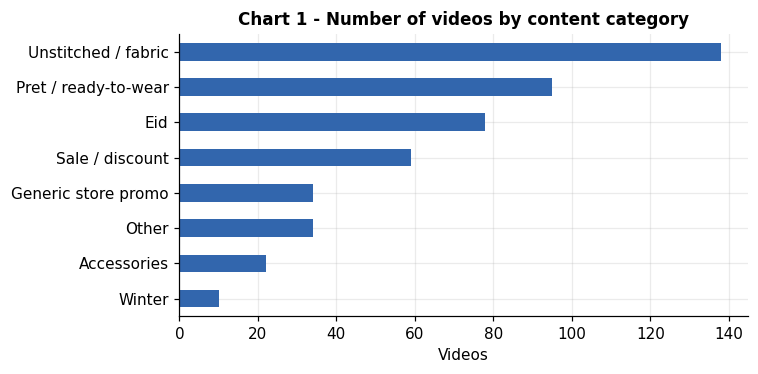

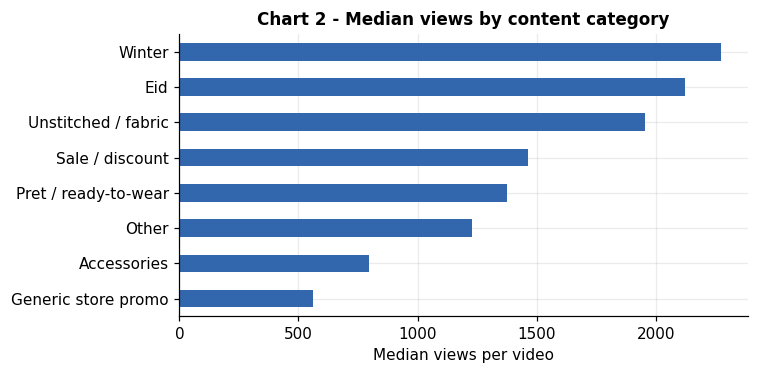

In [18]:
# Chart 1: how many videos per category (are the groups big enough to compare?)
order = cat.index.tolist()
ax = cat['videos'].plot(kind='barh', color=BLUE, figsize=(7, 3.5))
ax.invert_yaxis()
ax.set_title('Chart 1 - Number of videos by content category')
ax.set_xlabel('Videos'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

# Chart 2: median views by category (median, not mean - a few viral videos distort the mean)
ax = cat['median_views'].sort_values().plot(kind='barh', color=BLUE, figsize=(7, 3.5))
ax.set_title('Chart 2 - Median views by content category')
ax.set_xlabel('Median views per video'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

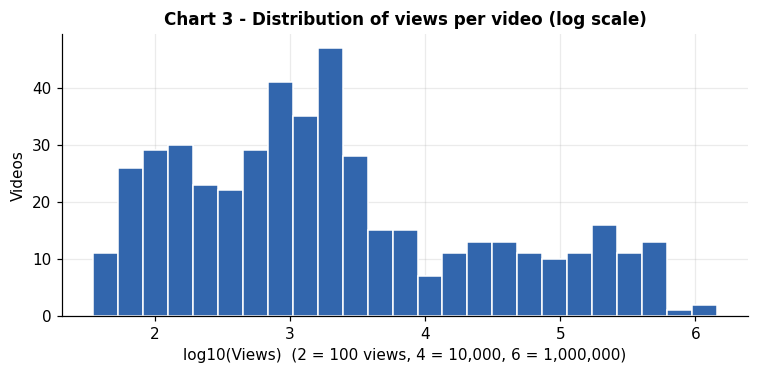

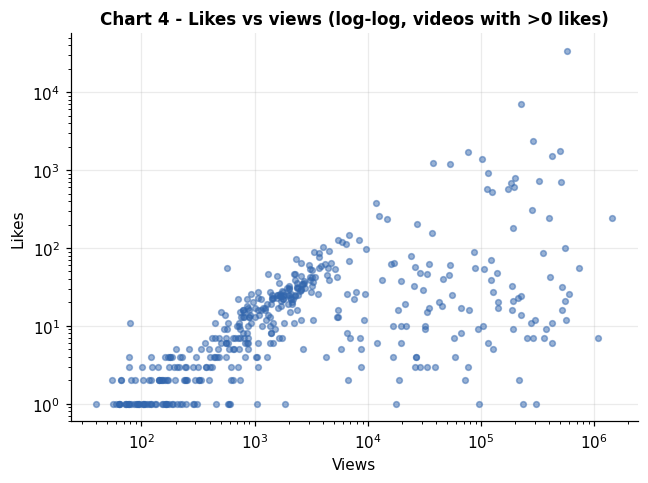

In [19]:
# Chart 3: distribution of views (log scale because the data is very skewed)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(df['Views']), bins=25, color=BLUE, edgecolor='white')
ax.set_title('Chart 3 - Distribution of views per video (log scale)')
ax.set_xlabel('log10(Views)  (2 = 100 views, 4 = 10,000, 6 = 1,000,000)'); ax.set_ylabel('Videos')
plt.tight_layout(); plt.show()

# Chart 4: likes vs views (log-log) - do more-viewed videos get more likes?
fig, ax = plt.subplots(figsize=(6, 4.5))
plot_df = df[df['Likes'] > 0]
ax.scatter(plot_df['Views'], plot_df['Likes'], s=14, alpha=0.5, color=BLUE)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Chart 4 - Likes vs views (log-log, videos with >0 likes)')
ax.set_xlabel('Views'); ax.set_ylabel('Likes')
plt.tight_layout(); plt.show()

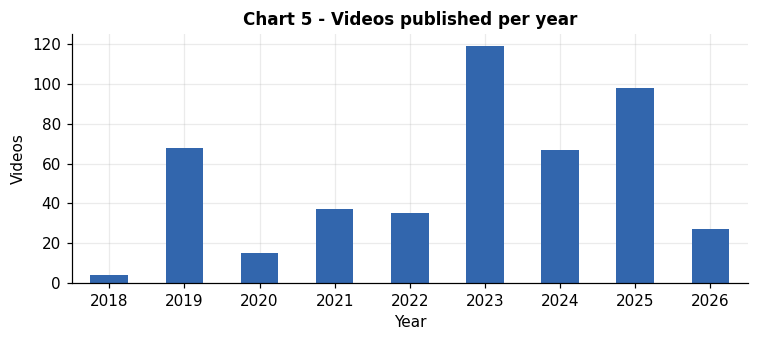

Median views by publish year (older videos have had longer to collect views):


,count,median
pub_year,,
2018,4,1124.0
2019,68,1816.0
2020,15,248.0
2021,37,1075.0
2022,35,1814.0
2023,119,450.0
2024,67,4239.0
2025,98,2004.0
2026,27,539.0


In [20]:
# Chart 5: how many videos were published each year (context for the sample)
ax = df['pub_year'].value_counts().sort_index().plot(kind='bar', color=BLUE, figsize=(7, 3.2))
ax.set_title('Chart 5 - Videos published per year')
ax.set_xlabel('Year'); ax.set_ylabel('Videos'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

print("Median views by publish year (older videos have had longer to collect views):")
display(df.groupby('pub_year')['Views'].agg(['count', 'median']).round(0))

## Step 6: Business interpretation
Numbers are not recommendations until they are explained. Each statement needs a **finding, evidence, action and limitation**.

> Do not say a category is best just because its total views or likes are higher. Check how many videos are in each group (Chart 1) and use the median.


### Final answer

**Observation 1** - Finding: A few videos dominate the averages. Mean views (about 45,000) are about 32 times the median (about 1,400), and the top 10 videos (2.1% of all videos) hold 33.6% of all views. Evidence: summary statistics in Step 4 and the views distribution in Chart 3.

**Observation 2** - Finding: Unstitched / fabric is the largest content category (138 videos) and gets a stronger audience response than most categories. Its median likes (17.5) are the highest of all categories, and its median like rate (1.13 likes per 100 views) is above the overall median (0.85). Evidence: the category table in Step 4 and Charts 1 and 2.

**Marketing recommendation:** In this dataset, unstitched / fabric videos have higher median likes and a higher like rate than the overall median. The brand could test more unstitched / fabric videos and compare them with other categories using a consistent metric (median views and likes per 100 views).

**Limitation:** The dataset has no reach, impressions or ad-spend information, older videos have had more time to collect views, and the content categories come from simple title keywords, so they are approximate.


## Step 7: Scaling experiment
This is a **scaling experiment**, not new evidence: the same 470 rows are repeated to make larger files, to see how loading time, analysis time, memory and file size change. The repeated rows tell us nothing new about Limelight.

We repeat the data 1x, 10x and 100x (about 470, 4,700 and 47,000 rows). The 1,000x run (about 470,000 rows) is optional because it needs more memory.

,repeat,rows,file_MB,load_s,groupby_s,sort_s,text_rules_s,memory_MB
0,1x,470,0.32,0.011,0.0017,0.0006,0.004,0.7
1,10x,4700,3.17,0.048,0.0024,0.0016,0.034,7.1
2,100x,47000,31.68,0.767,0.0122,0.0157,0.658,70.5


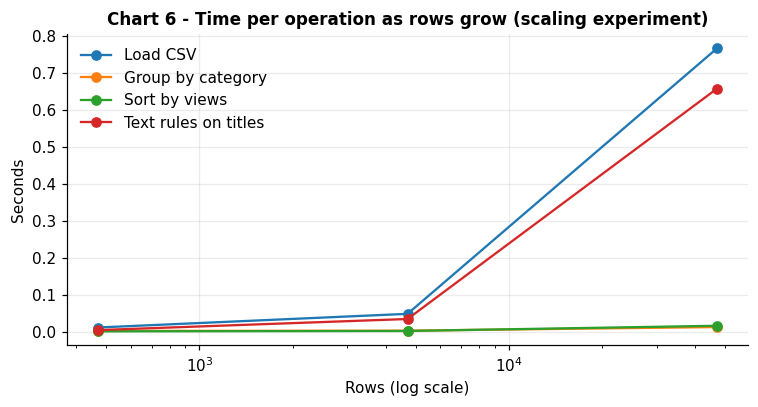

In [21]:
multipliers = [1, 10, 100]
# multipliers.append(1000)    # optional: ~470,000 rows - uncomment only if Colab memory allows

results = []
for m in multipliers:
    big = pd.concat([df] * m, ignore_index=True)
    fname = f'scale_{m}x.csv'
    big.to_csv(fname, index=False)

    t = time.time(); d = pd.read_csv(fname);                                   load = time.time() - t
    t = time.time(); d.groupby('category')[['Views', 'Likes']].median();       grp = time.time() - t
    t = time.time(); d.sort_values('Views', ascending=False).head();           srt = time.time() - t
    t = time.time(); d['Title'].map(categorize);                               txt = time.time() - t

    results.append({
        'repeat': f'{m}x',
        'rows': len(d),
        'file_MB': round(os.path.getsize(fname) / 1e6, 2),
        'load_s': round(load, 3),
        'groupby_s': round(grp, 4),
        'sort_s': round(srt, 4),
        'text_rules_s': round(txt, 3),
        'memory_MB': round(d.memory_usage(deep=True).sum() / 1e6, 1),
    })
    del big, d
    os.remove(fname)

res = pd.DataFrame(results)
display(res)

fig, ax = plt.subplots(figsize=(7, 3.8))
for col, label in [('load_s', 'Load CSV'), ('groupby_s', 'Group by category'),
                   ('sort_s', 'Sort by views'), ('text_rules_s', 'Text rules on titles')]:
    ax.plot(res['rows'], res[col], marker='o', label=label)
ax.set_xscale('log')
ax.set_title('Chart 6 - Time per operation as rows grow (scaling experiment)')
ax.set_xlabel('Rows (log scale)'); ax.set_ylabel('Seconds'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**What I observed:** The same 470-row dataset was repeated 1x, 10x and 100x (470, 4,700 and 47,000 rows) as a scaling experiment, not as new evidence. The file grew from 0.32 MB to 31.68 MB, and memory use grew from 0.7 MB to 70.5 MB, about 100 times for 100 times the rows. Loading time grew from 0.011 s to 0.767 s. The text-rule step (categorising titles) grew the most, from 0.004 s to 0.658 s, because it processes every title one by one, while group-by and sort stayed very fast (under 0.02 s). At this size nothing became inconvenient on my computer, but the trend shows that file size, memory and loading time grow roughly in proportion to the number of rows.

**Is a scalable tool needed?** Pandas can handle millions of rows on many computers, so there is no fixed row count where it "fails". Spark or another distributed tool becomes worth considering when the data no longer fits in memory, when operations take too long, or when many channels and platforms must be analysed repeatedly (for example daily refresh of all competitor brands plus Instagram, TikTok and Facebook). For these 470 videos, Pandas is enough.

## Step 8: Connect to analytics (short demo)
Classification, clustering and regression are possible follow-ups. A very small classification demo is below, mainly to show the **data-leakage rule**: the target (like rate) is built from Likes and Views, so Likes, Views and Comments are **not** used as input features. We also split data into train and test sets.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

m = df.dropna(subset=['duration_s']).copy()
m['high_like_rate'] = (m['like_rate_pct'] >= m['like_rate_pct'].median()).astype(int)   # label

X = pd.get_dummies(m[['category']]).astype(int).join(m[['duration_s', 'pub_year', 'title_len']])
y = m['high_like_rate']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
clf = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42).fit(X_train, y_train)

acc = accuracy_score(y_test, clf.predict(X_test))
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Test accuracy: {acc:.2f}   |   baseline (always guess the majority class): {baseline:.2f}")

Test accuracy: 0.60   |   baseline (always guess the majority class): 0.50


**Interpretation:** The model reached a test accuracy of 0.60 against a baseline of 0.50 (always guessing the majority class). This is only slightly better than guessing, so video category, duration, publish year and title length alone do not predict how well the audience responds (like rate). To predict response better, Limelight would need more information such as reach and impressions, audience size, posting time and whether a video was promoted with ads. To avoid data leakage, likes, views and comments were not used as input features, and the data was split into training and test sets.

**Exit question - which technique would help the marketing question, and what evidence would be needed?**
- *Classification* - predict high vs low response after defining a defensible label; needs richer features and a fair train/test split.
- *Clustering* - group videos with similar numeric features (views, likes, duration) to find segments; scale the features first.
- *Regression* - predict views or likes; needs more predictors than this dataset has.